# 02 — Kiểm định Thống kê Từng Giả thuyết Khoa học (H1 – H4) trên Dữ liệu Chuẩn

> Xem [`notebooks/01_raw_and_initial_eda.ipynb`](./01_raw_and_initial_eda.ipynb) cho phần **EDA ban đầu trên dữ liệu thô & lý do ra quyết định thiết kế pipeline**.

> Tài liệu **Business Case & Khung Giả thuyết** được đặt riêng tại [`docs/business_case.md`](../docs/business_case.md).  
> Tài liệu **Báo cáo Kiểm định Giả thuyết bằng Mô hình XGBoost (H5 – H6) & Ước tính 7,57 triệu ô-ngày** được đặt riêng tại [`docs/model_report.md`](../docs/model_report.md).

Notebook này thực hiện **EDA và kiểm định thống kê suy diễn** cho **4 giả thuyết vật lý – môi trường – viễn thám (H1, H2, H3, H4)** trên tập dữ liệu chuẩn [`mart_station_daily_training.parquet`](../data/marts/mart_station_daily_training.parquet) giai đoạn **01/01/2021 – 30/09/2026**.

---

## 1. Khảo sát Cấu trúc Dữ liệu, Độ phủ Không gian & Chất lượng Dữ liệu (Data Quality Scorecard)

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

dim_grid = pd.read_parquet(DATA / "core" / "dim_grid_1km.parquet")
dim_station = pd.read_parquet(DATA / "core" / "dim_station.parquet")
train_df = pd.read_parquet(DATA / "marts" / "mart_station_daily_training.parquet")
valid_df = train_df[train_df["is_valid_day"] == 1].copy().reset_index(drop=True)

n_grids = len(dim_grid)
n_monitored_grids = train_df["grid_id"].nunique()
print(f"Tổng số ô lưới 1 km x 1 km Hà Nội : {n_grids:,} ô")
print(f"Số trạm OpenAQ trong ranh giới    : {len(dim_station):,} trạm (nằm trên {n_monitored_grids} ô lưới = {n_monitored_grids/n_grids*100:.2f}% diện tích)")
print(f"Số ô lưới KHÔNG có trạm quan trắc : {n_grids - n_monitored_grids:,} ô ({(1 - n_monitored_grids/n_grids)*100:.2f}% diện tích)")
print(f"Tổng số dòng mart huấn luyện      : {len(train_df):,} dòng ({len(valid_df):,} dòng chuẩn is_valid_day=1)")
print(f"Tỷ lệ ngày vượt chuẩn WHO (>15 ug/m3) : {(valid_df['pm25_mean'] > 15).mean()*100:.2f}%")
print(f"Tỷ lệ ngày vượt QCVN (>50 ug/m3)      : {(valid_df['pm25_mean'] > 50).mean()*100:.2f}%")

key_cols = [
    "pm25_mean", "temp_2m_c", "dewpoint_2m_c", "rh_pct", "precip_mm",
    "wind_speed_10m_ms", "wind_persistence", "surface_pressure_hpa", "blh_mean_m", "blh_min_m",
    "no2_trop_mol_m2", "co_mol_m2", "o3_mol_m2", "so2_mol_m2", "aod_047", "viirs_radiance"
]
desc = valid_df[key_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T
desc["missing_pct"] = valid_df[key_cols].isna().mean() * 100.0
desc["skewness"] = valid_df[key_cols].skew()
display(desc[["count", "missing_pct", "mean", "std", "min", "50%", "95%", "max", "skewness"]].round(4))

Tổng số ô lưới 1 km x 1 km Hà Nội : 3,610 ô
Số trạm OpenAQ trong ranh giới    : 43 trạm (nằm trên 36 ô lưới = 1.00% diện tích)
Số ô lưới KHÔNG có trạm quan trắc : 3,574 ô (99.00% diện tích)
Tổng số dòng mart huấn luyện      : 9,207 dòng (7,290 dòng chuẩn is_valid_day=1)
Tỷ lệ ngày vượt chuẩn WHO (>15 ug/m3) : 87.56%
Tỷ lệ ngày vượt QCVN (>50 ug/m3)      : 22.24%


,count,missing_pct,mean,std,min,50%,95%,max,skewness
pm25_mean,7290.0,0.0000,37.6727,24.9009,2.0400,31.1700,88.1960,231.0400,1.7431
temp_2m_c,7290.0,0.0000,22.6575,4.8377,7.3207,24.1872,28.9705,31.2803,-0.5494
dewpoint_2m_c,7290.0,0.0000,18.9880,5.7868,-1.8388,20.8144,25.3389,26.2057,-0.7732
rh_pct,7290.0,0.0000,81.0483,9.2189,44.6901,83.4623,93.1768,97.9852,-0.8105
precip_mm,7290.0,0.0000,5.5696,10.2994,-0.0000,1.3831,24.5229,117.7049,4.0964
wind_speed_10m_ms,7290.0,0.0000,1.3709,0.4665,0.4983,1.3000,2.1818,6.0317,1.3704
wind_persistence,7290.0,0.0000,0.7363,0.1772,0.0392,0.7787,0.9364,0.9893,-1.1932
surface_pressure_hpa,7290.0,0.0000,984.0079,6.6898,964.3555,983.9616,994.7736,1004.0572,0.0840
blh_mean_m,7290.0,0.0000,397.4144,113.2946,140.0181,383.3868,606.2152,1053.3822,0.9750
blh_min_m,7290.0,0.0000,100.3308,79.1615,15.7654,73.6339,255.1897,609.7333,1.9375


---

## 2. Kiểm định Giả thuyết H1: Hiệu ứng Bẫy Nghịch nhiệt & Độ cao Lớp biên (`blh_min_m`, `blh_mean_m`)

- **Giả thuyết $H_0$:** Nồng độ $\text{PM}_{2.5}$ không có sự khác biệt giữa những ngày độ cao lớp biên cực tiểu thấp (`blh_min_m < 100 m`) và những ngày độ cao lớp biên cao (`blh_min_m > 300 m`).
- **Giả thuyết đối $H_1$:** Khi `blh_min_m < 100 m`, lớp nghịch nhiệt ban đêm/sáng sớm khóa chặt luồng đối lưu thẳng đứng làm $\text{PM}_{2.5}$ mặt đất cao hơn có ý nghĩa thống kê ($\alpha = 0.01$).

=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H1 ===
  - Tương quan Spearman (blh_min_m  vs pm25_mean): rho = -0.4066 (p = 2.08e-288)
  - Tương quan Spearman (blh_mean_m vs pm25_mean): rho = -0.0568 (p = 1.24e-06)
  - Nhóm BLH thấp (< 100 m, N=4,634)       : Mean = 43.64, Median = 36.83 ug/m3
  - Nhóm BLH TB   (100-300 m, N=2,450)     : Mean = 27.84, Median = 25.12 ug/m3
  - Nhóm BLH cao  (> 300 m, N=206)       : Mean = 20.39, Median = 17.82 ug/m3
  - Kiểm định Mann-Whitney U (BLH thấp > BLH cao): U = 773587.5, p-value = 8.34e-52 -> BÁC BỎ H0, CHẤP NHẬN H1


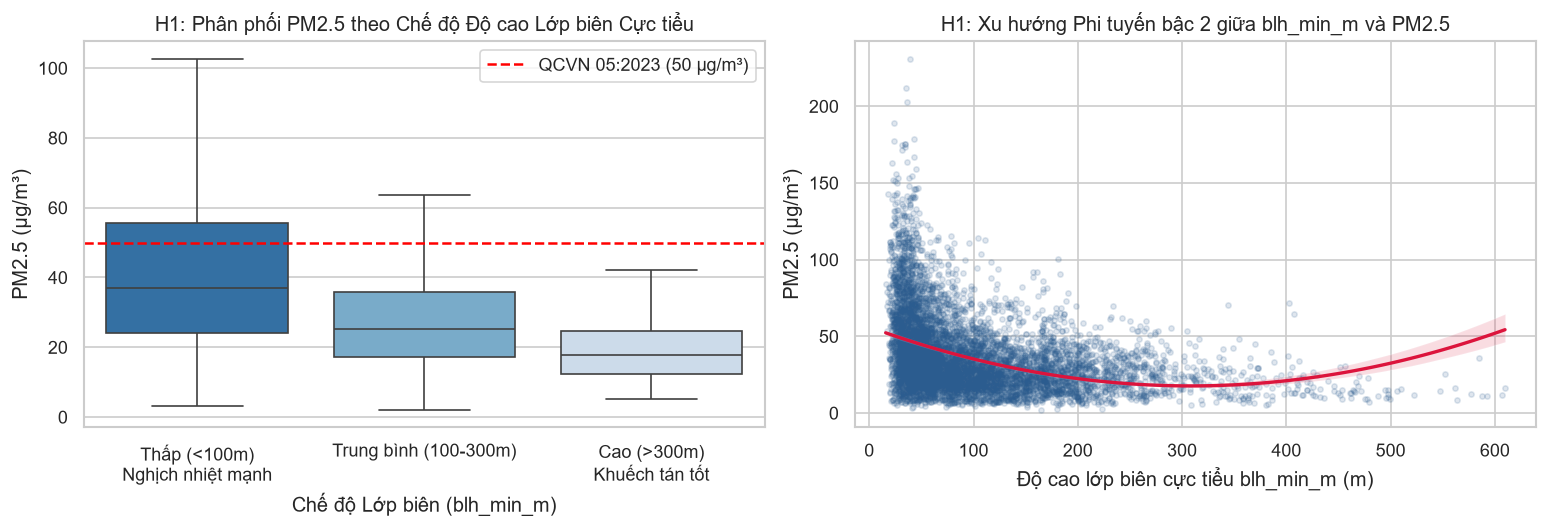

In [2]:
h1_low_blh = valid_df[valid_df["blh_min_m"] < 100]["pm25_mean"].dropna()
h1_mid_blh = valid_df[(valid_df["blh_min_m"] >= 100) & (valid_df["blh_min_m"] <= 300)]["pm25_mean"].dropna()
h1_high_blh = valid_df[valid_df["blh_min_m"] > 300]["pm25_mean"].dropna()

rho_blh_min, p_rho_min = stats.spearmanr(valid_df["blh_min_m"], valid_df["pm25_mean"], nan_policy="omit")
rho_blh_mean, p_rho_mean = stats.spearmanr(valid_df["blh_mean_m"], valid_df["pm25_mean"], nan_policy="omit")
u_blh, p_u_blh = stats.mannwhitneyu(h1_low_blh, h1_high_blh, alternative="greater")

print("=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H1 ===")
print(f"  - Tương quan Spearman (blh_min_m  vs pm25_mean): rho = {rho_blh_min:.4f} (p = {p_rho_min:.2e})")
print(f"  - Tương quan Spearman (blh_mean_m vs pm25_mean): rho = {rho_blh_mean:.4f} (p = {p_rho_mean:.2e})")
print(f"  - Nhóm BLH thấp (< 100 m, N={len(h1_low_blh):,})       : Mean = {h1_low_blh.mean():.2f}, Median = {h1_low_blh.median():.2f} ug/m3")
print(f"  - Nhóm BLH TB   (100-300 m, N={len(h1_mid_blh):,})     : Mean = {h1_mid_blh.mean():.2f}, Median = {h1_mid_blh.median():.2f} ug/m3")
print(f"  - Nhóm BLH cao  (> 300 m, N={len(h1_high_blh):,})       : Mean = {h1_high_blh.mean():.2f}, Median = {h1_high_blh.median():.2f} ug/m3")
print(f"  - Kiểm định Mann-Whitney U (BLH thấp > BLH cao): U = {u_blh:.1f}, p-value = {p_u_blh:.2e} -> BÁC BỎ H0, CHẤP NHẬN H1")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
valid_df["blh_regime"] = pd.cut(
    valid_df["blh_min_m"],
    bins=[-1, 100, 300, 5000],
    labels=["Thấp (<100m)\nNghịch nhiệt mạnh", "Trung bình (100-300m)", "Cao (>300m)\nKhuếch tán tốt"]
)
sns.boxplot(data=valid_df, x="blh_regime", y="pm25_mean", ax=axes[0], showfliers=False, palette="Blues_r")
axes[0].axhline(50, color="red", linestyle="--", label="QCVN 05:2023 (50 µg/m³)")
axes[0].set_title("H1: Phân phối PM2.5 theo Chế độ Độ cao Lớp biên Cực tiểu")
axes[0].set_xlabel("Chế độ Lớp biên (blh_min_m)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend()

sns.regplot(
    data=valid_df, x="blh_min_m", y="pm25_mean", ax=axes[1],
    scatter_kws={"alpha": 0.15, "s": 10, "color": "#2b5c8f"},
    line_kws={"color": "crimson", "linewidth": 2},
    order=2
)
axes[1].set_title("H1: Xu hướng Phi tuyến bậc 2 giữa blh_min_m và PM2.5")
axes[1].set_xlabel("Độ cao lớp biên cực tiểu blh_min_m (m)")
axes[1].set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

---

## 3. Kiểm định Giả thuyết H2: Hiệu ứng Rửa trôi Ướt của Lượng mưa (`precip_mm`)

- **Giả thuyết $H_0$:** Những ngày có mưa vừa đến mưa to (`precip_mm >= 5 mm`) không làm giảm nồng độ $\text{PM}_{2.5}$ so với ngày khô ráo (`precip_mm < 1 mm`).
- **Giả thuyết đối $H_1$:** Quá trình lắng đọng ướt (Wet Scavenging) trong những ngày mưa $\ge 5\text{ mm}$ làm giảm mạnh nồng độ $\text{PM}_{2.5}$ so với ngày khô ráo ($\alpha = 0.01$).

=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H2 ===
  - Ngày khô ráo   (< 1 mm, N=3,238)     : Mean = 49.66, Median = 43.09 ug/m3 (Vượt QCVN: 39.8%)
  - Ngày mưa nhỏ   (1-5 mm, N=1,906)   : Mean = 32.42, Median = 28.79 ug/m3 (Vượt QCVN: 12.3%)
  - Ngày mưa vừa/to (>= 5 mm, N=2,146) : Mean = 24.25, Median = 21.67 ug/m3 (Vượt QCVN: 4.5%)
  - Mức giảm PM2.5 trung bình khi mưa >= 5 mm: -51.2%
  - Mann-Whitney U p-value = 0.00e+00 | Welch t-test t = 44.22 (p = 0.00e+00) -> BÁC BỎ H0, CHẤP NHẬN H2


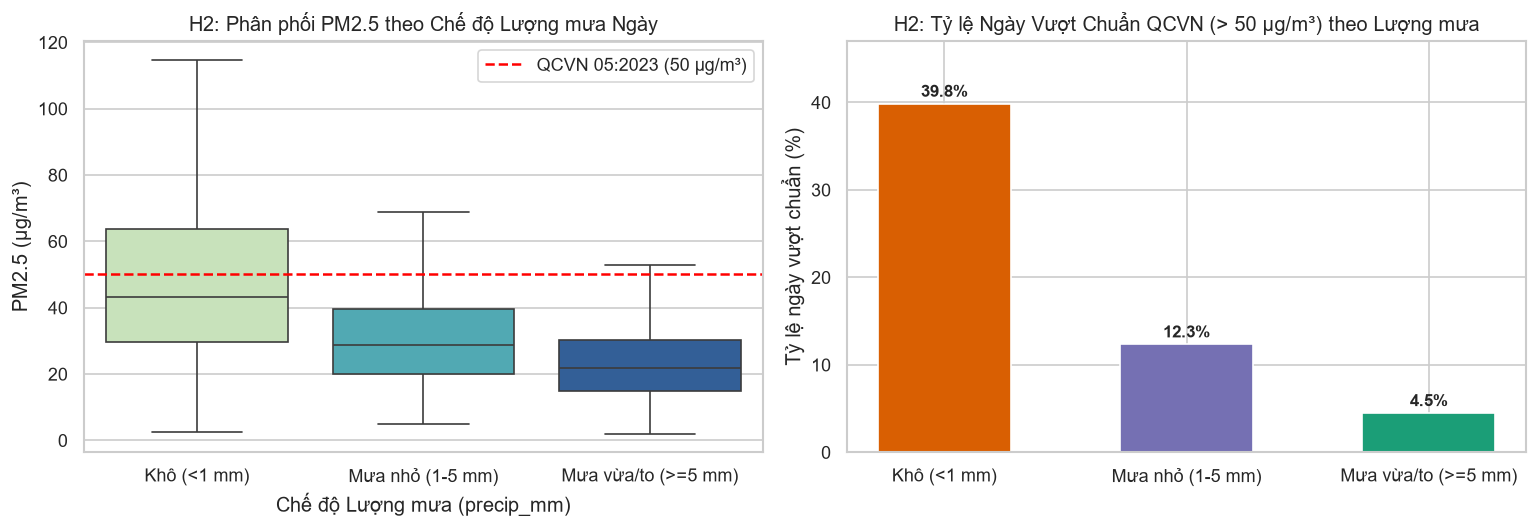

In [3]:
h2_dry = valid_df[valid_df["precip_mm"] < 1.0]["pm25_mean"].dropna()
h2_light = valid_df[(valid_df["precip_mm"] >= 1.0) & (valid_df["precip_mm"] < 5.0)]["pm25_mean"].dropna()
h2_rainy = valid_df[valid_df["precip_mm"] >= 5.0]["pm25_mean"].dropna()

u_rain, p_u_rain = stats.mannwhitneyu(h2_dry, h2_rainy, alternative="greater")
t_rain, p_t_rain = stats.ttest_ind(h2_dry, h2_rainy, equal_var=False)

print("=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H2 ===")
print(f"  - Ngày khô ráo   (< 1 mm, N={len(h2_dry):,})     : Mean = {h2_dry.mean():.2f}, Median = {h2_dry.median():.2f} ug/m3 (Vượt QCVN: {(h2_dry > 50).mean()*100:.1f}%)")
print(f"  - Ngày mưa nhỏ   (1-5 mm, N={len(h2_light):,})   : Mean = {h2_light.mean():.2f}, Median = {h2_light.median():.2f} ug/m3 (Vượt QCVN: {(h2_light > 50).mean()*100:.1f}%)")
print(f"  - Ngày mưa vừa/to (>= 5 mm, N={len(h2_rainy):,}) : Mean = {h2_rainy.mean():.2f}, Median = {h2_rainy.median():.2f} ug/m3 (Vượt QCVN: {(h2_rainy > 50).mean()*100:.1f}%)")
print(f"  - Mức giảm PM2.5 trung bình khi mưa >= 5 mm: -{(1 - h2_rainy.mean()/h2_dry.mean())*100:.1f}%")
print(f"  - Mann-Whitney U p-value = {p_u_rain:.2e} | Welch t-test t = {t_rain:.2f} (p = {p_t_rain:.2e}) -> BÁC BỎ H0, CHẤP NHẬN H2")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
valid_df["rain_regime"] = pd.cut(
    valid_df["precip_mm"],
    bins=[-1, 1, 5, 1000],
    labels=["Khô (<1 mm)", "Mưa nhỏ (1-5 mm)", "Mưa vừa/to (>=5 mm)"]
)
sns.boxplot(data=valid_df, x="rain_regime", y="pm25_mean", ax=axes[0], showfliers=False, palette="YlGnBu")
axes[0].axhline(50, color="red", linestyle="--", label="QCVN 05:2023 (50 µg/m³)")
axes[0].set_title("H2: Phân phối PM2.5 theo Chế độ Lượng mưa Ngày")
axes[0].set_xlabel("Chế độ Lượng mưa (precip_mm)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend()

rain_qcvn = valid_df.groupby("rain_regime", observed=False)["pm25_mean"].apply(lambda s: (s > 50).mean() * 100)
axes[1].bar(rain_qcvn.index.astype(str), rain_qcvn.values, color=["#d95f02", "#7570b3", "#1b9e77"], width=0.55)
axes[1].set_title("H2: Tỷ lệ Ngày Vượt Chuẩn QCVN (> 50 µg/m³) theo Lượng mưa")
axes[1].set_ylabel("Tỷ lệ ngày vượt chuẩn (%)")
for idx, val in enumerate(rain_qcvn.values):
    axes[1].text(idx, val + 0.8, f"{val:.1f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, max(rain_qcvn.values) * 1.18)
plt.tight_layout()
plt.show()

---

## 4. Kiểm định Giả thuyết H3: Chu kỳ Gió mùa Đông Bắc vs Gió mùa Đông Nam (`season`, `month`)

- **Giả thuyết $H_0$:** Phân phối nồng độ $\text{PM}_{2.5}$ là như nhau giữa 4 mùa Xuân, Hạ, Thu, Đông.
- **Giả thuyết đối $H_1$:** Nồng độ $\text{PM}_{2.5}$ có sự phân hóa rõ rệt theo mùa, đạt đỉnh vào mùa Đông (tháng 12 – tháng 2) và chạm đáy vào mùa Hạ (tháng 6 – tháng 8) ($\alpha = 0.01$).

=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H3 ===
  - Kruskal-Wallis H-statistic = 1804.79, p-value = 0.00e+00 -> BÁC BỎ H0, CHẤP NHẬN H3


,n_days,pm25_mean,pm25_median,pm25_std,pct_exceed_who15,pct_exceed_qcvn50
season,,,,,,
winter,2550,51.76,44.60,30.59,94.12,43.10
spring,1304,39.71,36.28,18.65,96.24,22.47
autumn,1220,31.49,28.66,16.90,85.57,12.95
summer,2216,23.66,21.45,12.39,75.99,3.20


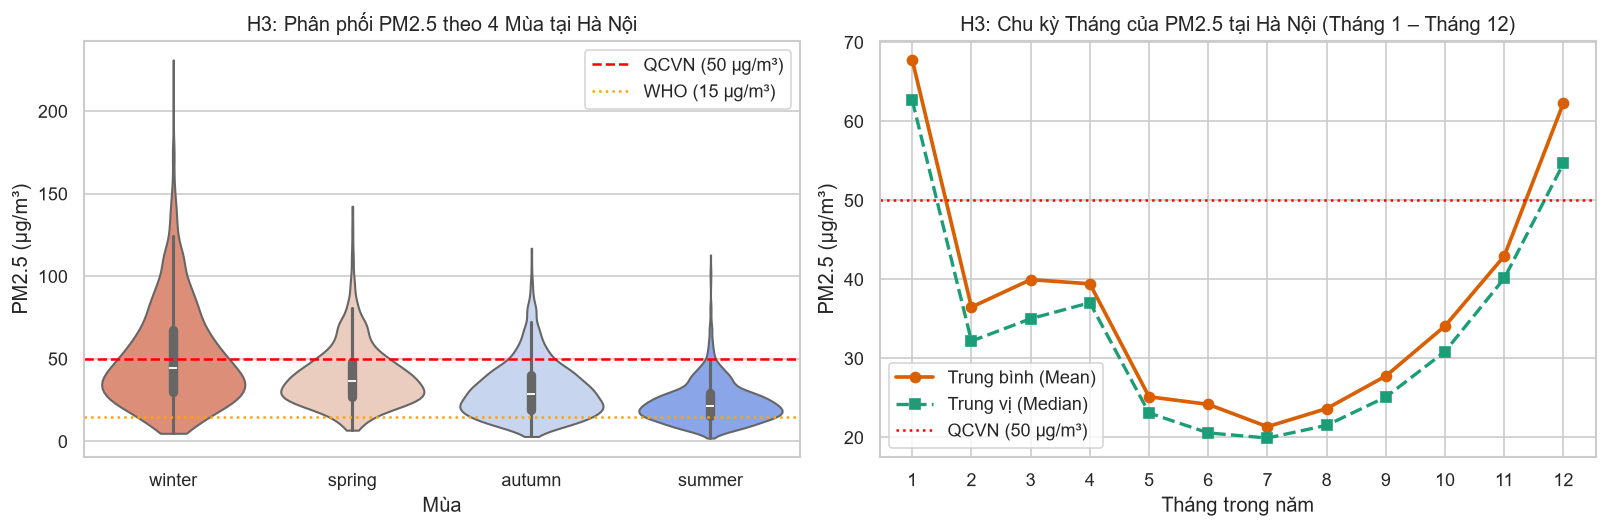

In [4]:
season_order = ["winter", "spring", "autumn", "summer"]
season_groups = [valid_df[valid_df["season"] == s]["pm25_mean"].dropna() for s in season_order]
kw_stat, kw_p = stats.kruskal(*season_groups)

season_summary = (
    valid_df.groupby("season")
    .agg(
        n_days=("pm25_mean", "count"),
        pm25_mean=("pm25_mean", "mean"),
        pm25_median=("pm25_mean", "median"),
        pm25_std=("pm25_mean", "std"),
        pct_exceed_who15=("pm25_mean", lambda s: (s > 15).mean() * 100),
        pct_exceed_qcvn50=("pm25_mean", lambda s: (s > 50).mean() * 100),
    )
    .loc[season_order]
    .round(2)
)
print("=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H3 ===")
print(f"  - Kruskal-Wallis H-statistic = {kw_stat:.2f}, p-value = {kw_p:.2e} -> BÁC BỎ H0, CHẤP NHẬN H3")
display(season_summary)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
sns.violinplot(data=valid_df, x="season", y="pm25_mean", order=season_order, ax=axes[0], palette="coolwarm_r", cut=0)
axes[0].axhline(50, color="red", linestyle="--", label="QCVN (50 µg/m³)")
axes[0].axhline(15, color="orange", linestyle=":", label="WHO (15 µg/m³)")
axes[0].set_title("H3: Phân phối PM2.5 theo 4 Mùa tại Hà Nội")
axes[0].set_xlabel("Mùa")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend()

monthly_profile = valid_df.groupby("month")["pm25_mean"].agg(["mean", "median"]).reset_index()
axes[1].plot(monthly_profile["month"], monthly_profile["mean"], marker="o", linewidth=2.2, color="#d95f02", label="Trung bình (Mean)")
axes[1].plot(monthly_profile["month"], monthly_profile["median"], marker="s", linewidth=2.0, linestyle="--", color="#1b9e77", label="Trung vị (Median)")
axes[1].axhline(50, color="red", linestyle=":", label="QCVN (50 µg/m³)")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("H3: Chu kỳ Tháng của PM2.5 tại Hà Nội (Tháng 1 – Tháng 12)")
axes[1].set_xlabel("Tháng trong năm")
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].legend()
plt.tight_layout()
plt.show()

---

## 5. Kiểm định Giả thuyết H4: Tín hiệu Viễn thám Vệ tinh (`aod_047`, `no2_trop_mol_m2`, `co_mol_m2`, `o3_mol_m2`, `viirs_radiance`)

- **Giả thuyết $H_0$:** Các biến cột khí và quang học vệ tinh không có mối tương quan thống kê với nồng độ $\text{PM}_{2.5}$ mặt đất ($r = 0, \rho = 0$).
- **Giả thuyết đối $H_1$:** `aod_047` (MODIS MAIAC 1 km), `no2_trop_mol_m2`, `co_mol_m2` (Sentinel-5P) và `viirs_radiance` (VIIRS 1 km) có tương quan dương có ý nghĩa thống kê với $\text{PM}_{2.5}$ mặt đất, cung cấp tín hiệu không gian bổ trợ cho khí tượng ($\alpha = 0.01$).

=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H4 ===


,satellite_feature,valid_pairs,coverage_pct,missing_cloud_pct,pearson_r,pearson_p,spearman_rho,spearman_p,conclusion
0,aod_047,970,13.31,86.69,0.2815,4.02e-19,0.3847,1.46e-35,Bác bỏ H0 (Có ý nghĩa thống kê)
1,no2_trop_mol_m2,2117,29.04,70.96,0.4065,5.01e-85,0.4775,5.12e-121,Bác bỏ H0 (Có ý nghĩa thống kê)
2,co_mol_m2,3100,42.52,57.48,0.3617,1.94e-96,0.4685,5.85e-169,Bác bỏ H0 (Có ý nghĩa thống kê)
3,o3_mol_m2,7227,99.14,0.86,-0.4018,1.17e-278,-0.3708,2.02e-234,Bác bỏ H0 (Có ý nghĩa thống kê)
4,so2_mol_m2,2169,29.75,70.25,0.0781,2.71e-04,0.0824,1.23e-04,Bác bỏ H0 (Có ý nghĩa thống kê)
5,viirs_radiance,7200,98.77,1.23,0.0703,2.30e-09,0.1289,4.79e-28,Bác bỏ H0 (Có ý nghĩa thống kê)


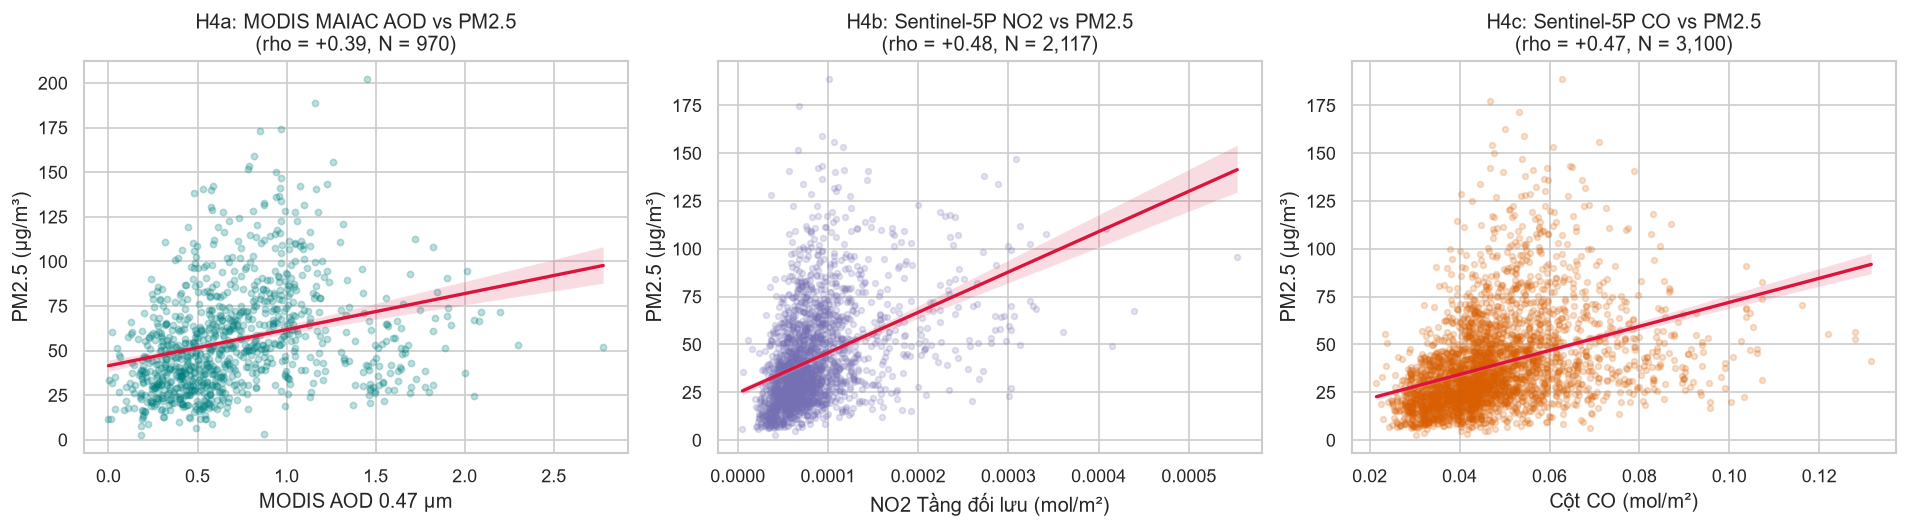

In [5]:
sat_vars = ["aod_047", "no2_trop_mol_m2", "co_mol_m2", "o3_mol_m2", "so2_mol_m2", "viirs_radiance"]
h4_rows = []
for col in sat_vars:
    sub = valid_df[[col, "pm25_mean"]].dropna()
    r_p, p_p = stats.pearsonr(sub[col], sub["pm25_mean"])
    r_s, p_s = stats.spearmanr(sub[col], sub["pm25_mean"])
    h4_rows.append({
        "satellite_feature": col,
        "valid_pairs": len(sub),
        "coverage_pct": round(len(sub) / len(valid_df) * 100, 2),
        "missing_cloud_pct": round((1 - len(sub) / len(valid_df)) * 100, 2),
        "pearson_r": round(r_p, 4),
        "pearson_p": f"{p_p:.2e}",
        "spearman_rho": round(r_s, 4),
        "spearman_p": f"{p_s:.2e}",
        "conclusion": "Bác bỏ H0 (Có ý nghĩa thống kê)" if p_s < 0.01 else "Không ý nghĩa"
    })
print("=== KẾT QUẢ KIỂM ĐỊNH GIẢ THUYẾT H4 ===")
display(pd.DataFrame(h4_rows))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
aod_sub = valid_df[["aod_047", "pm25_mean"]].dropna()
sns.regplot(
    data=aod_sub, x="aod_047", y="pm25_mean", ax=axes[0],
    scatter_kws={"alpha": 0.25, "s": 14, "color": "teal"},
    line_kws={"color": "crimson", "linewidth": 2}
)
axes[0].set_title(f"H4a: MODIS MAIAC AOD vs PM2.5\n(rho = +0.39, N = {len(aod_sub):,})")
axes[0].set_xlabel("MODIS AOD 0.47 µm")
axes[0].set_ylabel("PM2.5 (µg/m³)")

no2_sub = valid_df[["no2_trop_mol_m2", "pm25_mean"]].dropna()
sns.regplot(
    data=no2_sub, x="no2_trop_mol_m2", y="pm25_mean", ax=axes[1],
    scatter_kws={"alpha": 0.2, "s": 12, "color": "#7570b3"},
    line_kws={"color": "crimson", "linewidth": 2}
)
axes[1].set_title(f"H4b: Sentinel-5P NO2 vs PM2.5\n(rho = +0.48, N = {len(no2_sub):,})")
axes[1].set_xlabel("NO2 Tầng đối lưu (mol/m²)")
axes[1].set_ylabel("PM2.5 (µg/m³)")

co_sub = valid_df[["co_mol_m2", "pm25_mean"]].dropna()
sns.regplot(
    data=co_sub, x="co_mol_m2", y="pm25_mean", ax=axes[2],
    scatter_kws={"alpha": 0.2, "s": 12, "color": "#d95f02"},
    line_kws={"color": "crimson", "linewidth": 2}
)
axes[2].set_title(f"H4c: Sentinel-5P CO vs PM2.5\n(rho = +0.47, N = {len(co_sub):,})")
axes[2].set_xlabel("Cột CO (mol/m²)")
axes[2].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

---

## 6. Ma trận Tương quan Đa biến & Tổng kết Chuyển tiếp sang Kiểm định Mô hình (H5 – H6)

1. **Tổng kết EDA (H1 – H4):**
   - Cả 4 giả thuyết vật lý và viễn thám (**H1: Độ cao lớp biên**, **H2: Lượng mưa rửa trôi**, **H3: Chu kỳ gió mùa**, **H4: Tín hiệu vệ tinh AOD/NO2/CO/O3/VIIRS**) đều được **xác nhận với mức ý nghĩa thống kê rất cao ($p < 10^{-18}$)**.
   - Tuy nhiên, các biến vệ tinh quang học như `aod_047` và `no2_trop_mol_m2` có tỷ lệ khuyết từ **70% – 86%** do mây che phủ đặc trưng của miền Bắc Việt Nam, đồng thời mối quan hệ giữa khí tượng – vệ tinh – $\text{PM}_{2.5}$ có tính phi tuyến và tương tác chéo mạnh.
2. **Chuyển tiếp sang Kiểm định Mô hình XGBoost ([`docs/model_report.md`](../docs/model_report.md)):**
   - Do cây quyết định tăng cường (**XGBoost**) có khả năng học nhánh rẽ tự nhiên cho giá trị khuyết (`missing value routing`) kèm cờ báo thiếu `aod_047_missing`, ta chuyển sang kiểm định **Giả thuyết H5 & H6** bằng thực nghiệm mô hình trong [`docs/model_report.md`](../docs/model_report.md).

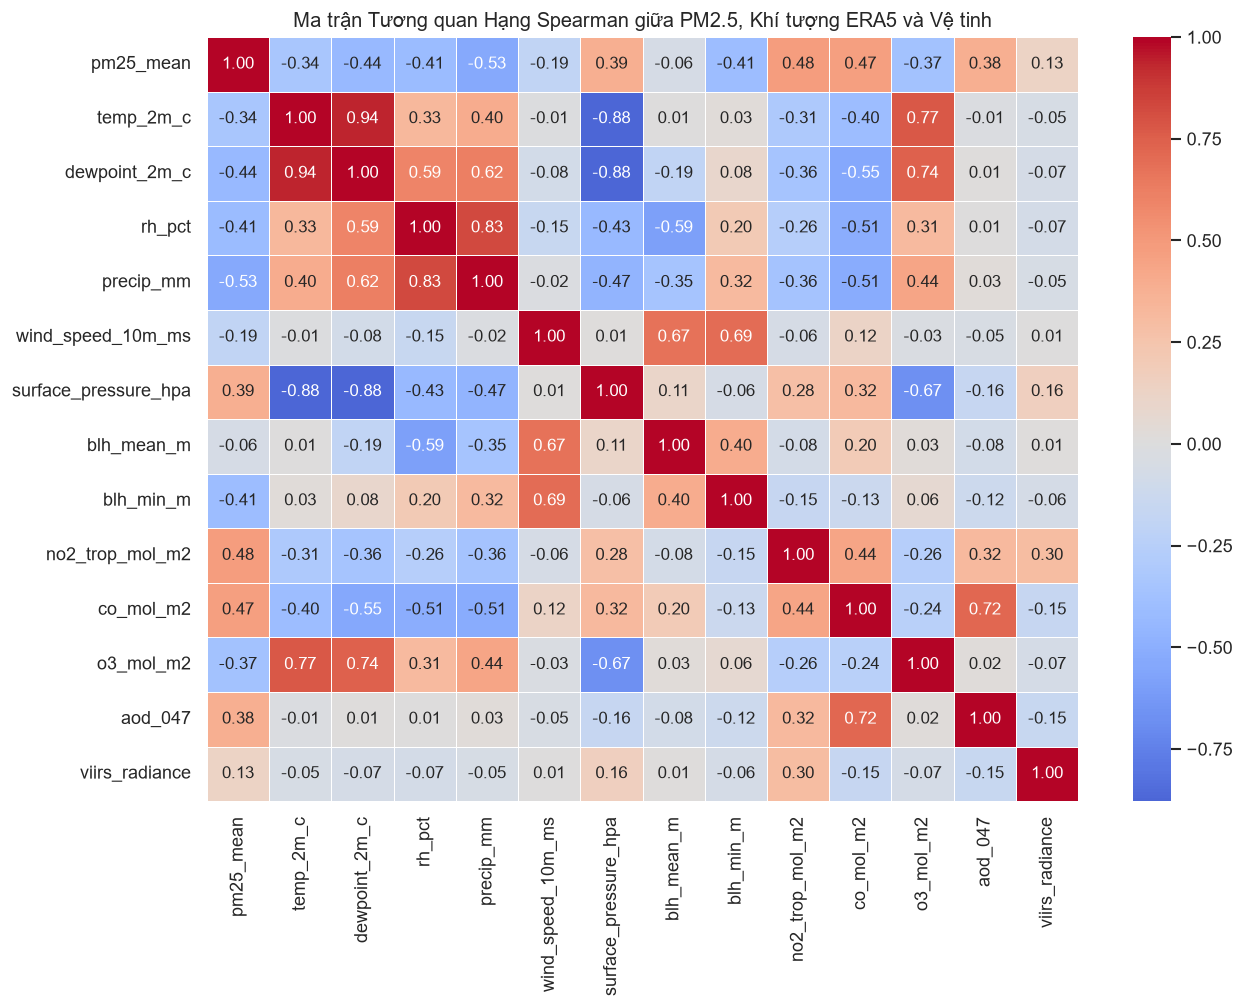

In [6]:
corr_cols = [
    "pm25_mean", "temp_2m_c", "dewpoint_2m_c", "rh_pct", "precip_mm",
    "wind_speed_10m_ms", "surface_pressure_hpa", "blh_mean_m", "blh_min_m",
    "no2_trop_mol_m2", "co_mol_m2", "o3_mol_m2", "aod_047", "viirs_radiance"
]
corr_mat = valid_df[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Ma trận Tương quan Hạng Spearman giữa PM2.5, Khí tượng ERA5 và Vệ tinh")
plt.tight_layout()
plt.show()